# Gaussian Processes for Time Series with GPyTorch

by [Richard Cornelius Suwandi](https://richardcsuwandi.github.io/)

<img src="https://raw.githubusercontent.com/richardcsuwandi/gp-time-series-tutorial/main/assets/gp_banner.png" alt="GPyTorch" width="100%">

In this notebook we fit Gaussian processes (GPs) to real time series using [GPyTorch](https://gpytorch.ai), a GP library built on top of PyTorch. A GP model is just a small class, training is a normal PyTorch loop, and kernels can be mixed and matched like Lego blocks.

> 💡 **The main message.** The kernel is the model. The same GP with a different kernel can give a useless forecast or an excellent one.

**What you will do**
* 🧠 Build intuition for GPs and kernels with plots and sliders
* 🛠️ Learn the GPyTorch building blocks (model, kernels, training loop)
* 📈 Forecast Mauna Loa CO$_2$ by designing a kernel step by step
* ✏️ Design your own kernel for real wireless traffic from Huawei
* 🤖 See the kernel an LLM agent discovered for the same data, and try to beat it

**Plan**
1. A short GP recap
2. The GPyTorch building blocks (model, kernels, training loop)
3. Worked example with the Mauna Loa CO$_2$ dataset
4. Your turn with real wireless traffic data from Huawei
5. Can an LLM design the kernel for us?

> **Running on Google Colab.** Use *Runtime → Run all*. Colab already has PyTorch, and the next cell installs GPyTorch. Cells marked 🎛️ have sliders, so play with them.

<table><tr>
<td>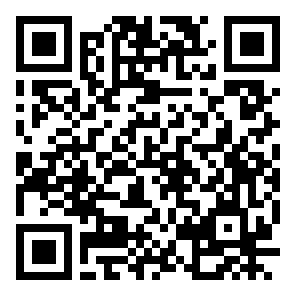</td>
<td style="font-size: 1.15em; padding-left: 16px;">📱 <b>Follow along!</b><br><br>Open <a href="https://github.com/richardcsuwandi/gp-time-series-tutorial">github.com/richardcsuwandi/gp-time-series-tutorial</a><br>or scan the QR code, then click <i>Open in Colab</i>.</td>
</tr></table>


In [1]:
%pip install -q gpytorch

You should consider upgrading via the '/private/tmp/claude-501/-Users-richardsuwandi-github-richardcsuwandi-github-io/4946c9f4-731d-4334-9425-9d4fabadb24e/scratchpad/venv/bin/python -m pip install --upgrade pip' command.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import gpytorch
from gpytorch.kernels import RBFKernel, MaternKernel, PeriodicKernel, RQKernel, LinearKernel, ScaleKernel
from ipywidgets import interact, Dropdown, FloatSlider

torch.set_default_dtype(torch.float64)  # GPs are more stable in double precision
torch.manual_seed(0)
plt.rcParams["figure.figsize"] = (11, 3.5)

## 1. A short GP recap

A Gaussian process is a **distribution over functions**. We write

$$f \sim GP\big(m(x),\, k(x, x')\big).$$

* $m(x)$ is the mean function, usually a constant.
* $k(x, x')$ is the **kernel**, also called the covariance function. It says how similar $f(x)$ and $f(x')$ should be. All our assumptions about the data live here. Is the signal smooth or rough? Does it repeat? Does it have a trend?
* We observe noisy data $y_i = f(x_i) + \varepsilon_i$ with $\varepsilon_i \sim N(0, \sigma^2)$.

**Training.** The kernel has hyperparameters $\theta$ (lengthscales, periods, variances). We learn them by maximizing the log marginal likelihood

$$\log p(\mathbf{y} \mid X, \theta) = -\tfrac{1}{2}\mathbf{y}^\top (K_\theta + \sigma^2 I)^{-1}\mathbf{y} - \tfrac{1}{2}\log\lvert K_\theta + \sigma^2 I\rvert - \tfrac{n}{2}\log 2\pi .$$

* The first term rewards fitting the data.
* The second term penalizes overly complex models.
* In PyTorch this is just a loss we minimize with gradient descent.

**Prediction.** Given the training data, the prediction at new inputs is again Gaussian, so every forecast comes with an uncertainty band for free.

### From prior to posterior

Here is the whole idea in one picture, written in plain PyTorch.
* **Before any data**, the GP spreads its bets over many functions.
* **Each observation** pins the functions down near it, so the uncertainty shrinks there.
* **Far from the data**, the GP falls back to the prior and admits it does not know.

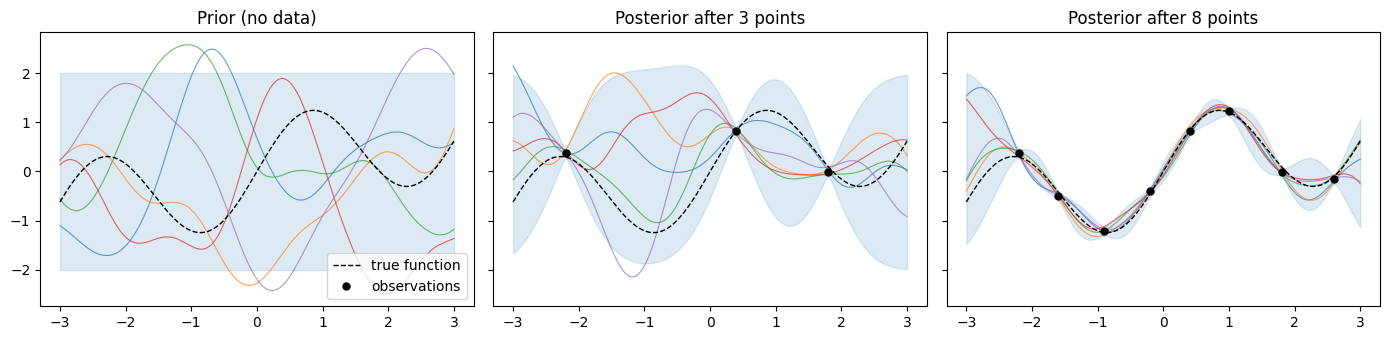

In [3]:
def rbf(a, b, lengthscale=0.6):
    return torch.exp(-0.5 * (a[:, None] - b[None, :]) ** 2 / lengthscale**2)

f_true = lambda x: torch.sin(2 * x) + 0.3 * x
x_pool = torch.tensor([-2.2, 0.4, 1.8, -0.9, 2.6, -1.6, 1.0, -0.2])
y_pool = f_true(x_pool) + 0.05 * torch.randn(len(x_pool))
x_star = torch.linspace(-3, 3, 200)
noise_var = 0.05**2

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, n in zip(axes, [0, 3, 8]):
    x_obs, y_obs = x_pool[:n], y_pool[:n]
    K = rbf(x_obs, x_obs) + noise_var * torch.eye(n)
    K_star = rbf(x_star, x_obs)
    mean = K_star @ torch.linalg.solve(K, y_obs)  # posterior mean
    cov = rbf(x_star, x_star) - K_star @ torch.linalg.solve(K, K_star.T)  # posterior covariance
    std = cov.diag().clamp_min(0).sqrt()
    samples = gpytorch.distributions.MultivariateNormal(mean, cov + 1e-6 * torch.eye(len(x_star))).sample(torch.Size([5]))

    ax.plot(x_star, samples.T, lw=0.8, alpha=0.7)
    ax.fill_between(x_star, mean - 2 * std, mean + 2 * std, color="tab:blue", alpha=0.15)
    ax.plot(x_star, f_true(x_star), "k--", lw=1, label="true function")
    ax.plot(x_obs, y_obs, "ko", ms=5, label="observations")
    ax.set_title("Prior (no data)" if n == 0 else f"Posterior after {n} points")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

## 2. GPyTorch building blocks

### 2.1 The model

A GPyTorch model is a PyTorch module with a mean and a kernel. We pass the kernel in as an argument, so that trying a new kernel is a one-line change.

In [4]:
class GPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, kernel):
        likelihood = gpytorch.likelihoods.GaussianLikelihood()  # learns the noise variance
        super().__init__(train_x, train_y, likelihood)
        self.mean_module = gpytorch.means.ConstantMean()
        self.covar_module = kernel

    def forward(self, x):
        mean = self.mean_module(x)
        covar = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean, covar)

### 2.2 Kernels

GPyTorch ships with the classic kernels, and you combine them with `+` and `*`.

| Kernel | Assumption about the function |
|---|---|
| `RBFKernel` | very smooth, varies on a length scale $\ell$ |
| `MaternKernel(nu=0.5, 1.5, 2.5)` | smooth but rougher than RBF (smaller `nu` means rougher) |
| `PeriodicKernel` | repeats exactly every `period_length` |
| `RQKernel` | mixture of many length scales |
| `LinearKernel` | linear trend |
| `ScaleKernel(k)` | wraps `k` and learns its overall variance (outputscale) |

The rules for combining them are intuitive.
* **Sum** `k1 + k2` means the function is a sum of two independent parts (for example trend plus seasonality).
* **Product** `k1 * k2` means one behavior modulates the other (for example a periodic pattern whose shape slowly changes over time).

The quickest way to understand a kernel is to draw random functions from the prior. You can set initial hyperparameters with `.initialize(...)`.

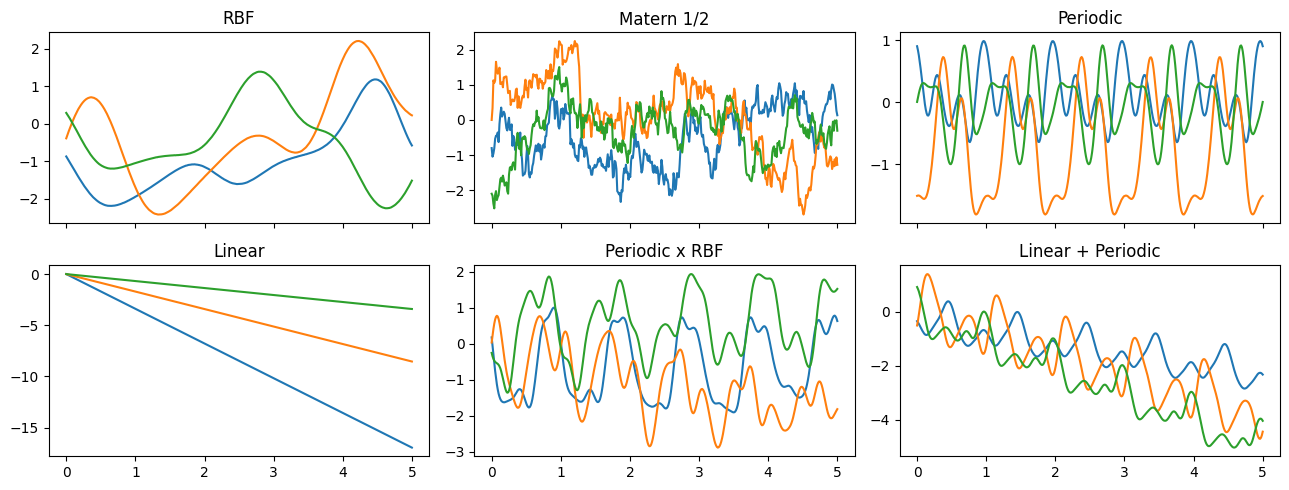

In [5]:
x_grid = torch.linspace(0, 5, 400)
prior_kernels = {
    "RBF": RBFKernel().initialize(lengthscale=0.5),
    "Matern 1/2": MaternKernel(nu=0.5).initialize(lengthscale=0.5),
    "Periodic": PeriodicKernel().initialize(period_length=1.0),
    "Linear": LinearKernel(),
    "Periodic x RBF": PeriodicKernel().initialize(period_length=1.0) * RBFKernel().initialize(lengthscale=2.0),
    "Linear + Periodic": LinearKernel() + PeriodicKernel().initialize(period_length=1.0),
}

fig, axes = plt.subplots(2, 3, figsize=(13, 5), sharex=True)
for ax, (name, k) in zip(axes.flat, prior_kernels.items()):
    with torch.no_grad():
        K = k(x_grid).to_dense() + 1e-6 * torch.eye(len(x_grid))
        samples = gpytorch.distributions.MultivariateNormal(torch.zeros(len(x_grid)), K).sample(torch.Size([3]))
    ax.plot(x_grid, samples.T)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### 🎛️ Play with a kernel

Left is the kernel $k(0, x)$, right are random functions it generates. Try these.
* `RBF` vs `Matern 1/2` with a small `lengthscale`. Which one is rougher?
* `Periodic x RBF` with a shrinking `lengthscale`. The repeating pattern starts to drift.

In [6]:
def make_kernel(name, lengthscale, period):
    if name == "RBF":
        return RBFKernel().initialize(lengthscale=lengthscale)
    if name == "Matern 1/2":
        return MaternKernel(nu=0.5).initialize(lengthscale=lengthscale)
    if name == "Matern 5/2":
        return MaternKernel(nu=2.5).initialize(lengthscale=lengthscale)
    if name == "Periodic":
        return PeriodicKernel().initialize(period_length=period, lengthscale=lengthscale)
    if name == "Periodic x RBF":
        return PeriodicKernel().initialize(period_length=period) * RBFKernel().initialize(lengthscale=lengthscale)
    if name == "Linear + Periodic":
        return LinearKernel() + PeriodicKernel().initialize(period_length=period, lengthscale=lengthscale)


@interact(kernel=Dropdown(options=["RBF", "Matern 1/2", "Matern 5/2", "Periodic", "Periodic x RBF", "Linear + Periodic"], value="Periodic x RBF"),
          lengthscale=FloatSlider(value=1.0, min=0.05, max=3.0, step=0.05),
          period=FloatSlider(value=1.0, min=0.2, max=3.0, step=0.1))
def explore_kernel(kernel, lengthscale, period):
    k = make_kernel(kernel, lengthscale, period)
    x_grid = torch.linspace(0, 5, 300)
    with torch.no_grad():
        k0 = k(x_grid[:1], x_grid).to_dense().squeeze(0)
        K = k(x_grid).to_dense() + 1e-6 * torch.eye(len(x_grid))
        torch.manual_seed(1)  # same random seed, so only the kernel changes the picture
        samples = gpytorch.distributions.MultivariateNormal(torch.zeros(len(x_grid)), K).sample(torch.Size([3]))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={"width_ratios": [1, 2]})
    ax1.plot(x_grid, k0, color="black")
    ax1.set_title("kernel $k(0, x)$")
    ax1.set_xlabel("x")
    ax2.plot(x_grid, samples.T)
    ax2.set_title(f"samples from {kernel}")
    ax2.set_xlabel("x")
    plt.tight_layout()
    plt.show()

interactive(children=(Dropdown(description='kernel', index=4, options=('RBF', 'Matern 1/2', 'Matern 5/2', 'Per…

### 2.3 Training and prediction

Training is a standard PyTorch loop. The loss is the negative marginal likelihood (GPyTorch divides it by the number of points, so the numbers stay small).

In [7]:
def train(model, iters=300, lr=0.05, verbose=True):
    x, y = model.train_inputs[0], model.train_targets
    mll = gpytorch.mlls.ExactMarginalLogLikelihood(model.likelihood, model)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for i in range(iters):
        optimizer.zero_grad()
        loss = -mll(model(x), y)
        loss.backward()
        optimizer.step()
        if verbose and (i % 100 == 0 or i == iters - 1):
            print(f"iter {i:4d}   loss {loss.item():.3f}")
    return model


def predict(model, x):
    model.eval()
    with torch.no_grad():
        pred = model.likelihood(model(x))  # includes observation noise
    return pred.mean, pred.variance.sqrt()


def score(model, x_test, y_test):
    # RMSE checks the mean, NLPD (negative log predictive density) also checks the uncertainty. Lower is better for both.
    mean, std = predict(model, x_test)
    rmse = (mean - y_test).pow(2).mean().sqrt().item()
    nlpd = -torch.distributions.Normal(mean, std).log_prob(y_test).mean().item()
    return rmse, nlpd


def plot_fit(model, x_train, y_train, x_test, y_test, title="", y_mean=0.0, y_std=1.0, xlabel="x", ylabel="y"):
    x_all = torch.cat([x_train, x_test])
    mean, std = predict(model, x_all)
    un = lambda v: v * y_std + y_mean  # undo standardization for plotting
    plt.figure()
    plt.plot(x_train, un(y_train), "k.", ms=2, label="train")
    plt.plot(x_test, un(y_test), ".", color="tab:red", ms=2, label="test")
    plt.plot(x_all, un(mean), color="tab:blue", label="GP mean")
    plt.fill_between(x_all, un(mean - 2 * std), un(mean + 2 * std), color="tab:blue", alpha=0.2, label="±2 std")
    plt.axvline(x_test[0].item(), color="gray", ls="--")
    rmse, nlpd = score(model, x_test, y_test)
    plt.title(f"{title}   (test RMSE {rmse:.3f}, NLPD {nlpd:.3f})")
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.legend(loc="upper left")
    plt.show()

## 3. Worked example with Mauna Loa CO$_2$

This dataset contains monthly atmospheric CO$_2$ measurements at the Mauna Loa Observatory in Hawaii from 1958 to 2001. It is the classic example for kernel design (see the [scikit-learn version](https://scikit-learn.org/stable/auto_examples/gaussian_process/plot_gpr_co2.html) of this example). We train on data before 1990 and ask the GP to **forecast** the following 12 years.

377 training months, 144 test months


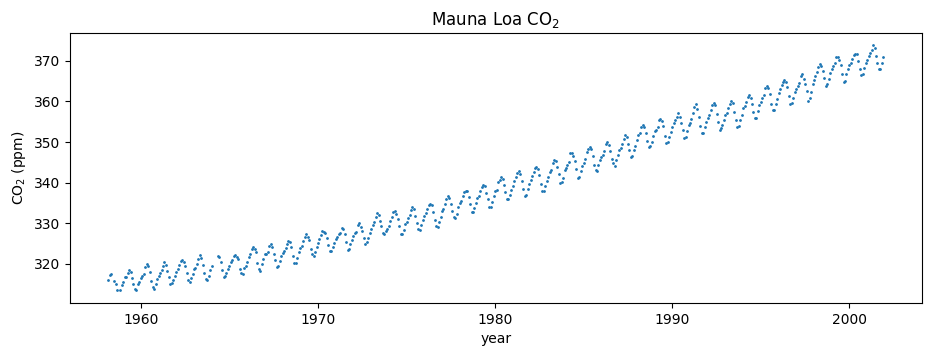

In [8]:
from sklearn.datasets import fetch_openml

co2 = fetch_openml(data_id=41187, as_frame=True).frame
monthly = co2.groupby(["year", "month"])["co2"].mean().reset_index()
years = (monthly["year"] + (monthly["month"] - 1) / 12).to_numpy()

x = torch.tensor(years - 1958.0)  # input = years since 1958
y_raw = torch.tensor(monthly["co2"].to_numpy())

train_mask = years < 1990
y_mean, y_std = y_raw[train_mask].mean(), y_raw[train_mask].std()
y = (y_raw - y_mean) / y_std  # standardize the targets, which makes optimization easier

x_train, y_train = x[train_mask], y[train_mask]
x_test, y_test = x[~train_mask], y[~train_mask]
print(f"{len(x_train)} training months, {len(x_test)} test months")

plt.plot(years, y_raw, ".", ms=2)
plt.xlabel("year")
plt.ylabel("CO$_2$ (ppm)")
plt.title("Mauna Loa CO$_2$")
plt.show()

**Look at the data before choosing a kernel.** We can see three patterns.
* A **smooth rising trend**
* A **yearly seasonal cycle**
* Some **small irregular wiggles**

### Attempt 1. A plain RBF kernel

Let us first try the default choice that many people use without thinking.

iter    0   loss 0.904


iter  100   loss -0.224


iter  200   loss -0.242


iter  299   loss -0.247


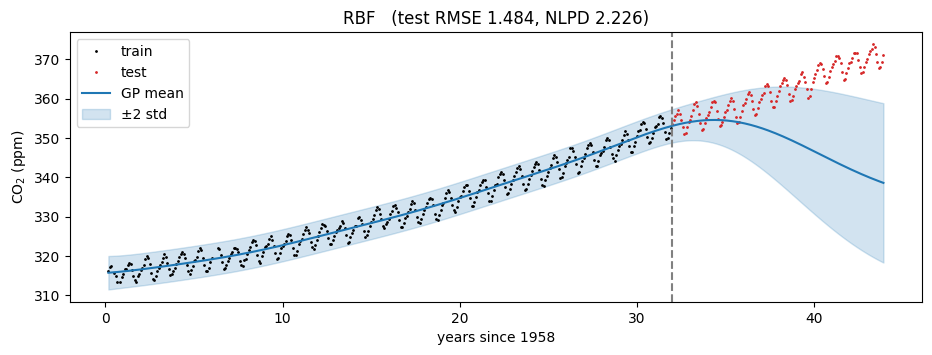

In [9]:
model_rbf = train(GPModel(x_train, y_train, ScaleKernel(RBFKernel())))
plot_fit(model_rbf, x_train, y_train, x_test, y_test, "RBF", y_mean, y_std, "years since 1958", "CO$_2$ (ppm)")

The RBF kernel fits the training data, but the forecast quickly falls back to the mean.
* An RBF kernel only knows that **nearby points are similar**.
* It has no idea that the trend continues or that the seasons repeat.

### Attempt 2. A kernel designed from what we see

We build one kernel component for each pattern, with sensible initial values in units of years.

| Pattern | Kernel component | Initial value |
|---|---|---|
| Trend | long RBF | lengthscale 50 years |
| Seasonality | Periodic × long RBF, so the seasonal shape can slowly change | period 1 year |
| Irregularities | rational quadratic (RQ) for medium-term wiggles | lengthscale 1 year |
| Noise | Gaussian likelihood | learned |

iter    0   loss 0.876


iter  100   loss -1.486


iter  200   loss -1.543


iter  299   loss -2.175


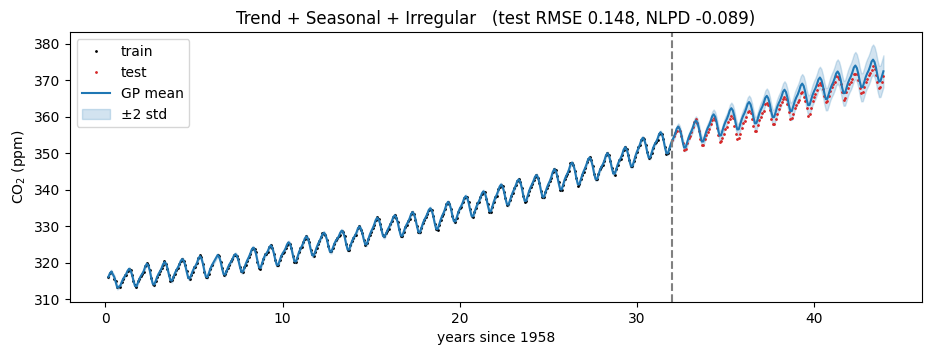

In [10]:
trend = ScaleKernel(RBFKernel().initialize(lengthscale=50.0))
seasonal = ScaleKernel(PeriodicKernel().initialize(period_length=1.0) * RBFKernel().initialize(lengthscale=100.0))
irregular = ScaleKernel(RQKernel().initialize(lengthscale=1.0, alpha=1.0))

model_co2 = train(GPModel(x_train, y_train, trend + seasonal + irregular))
plot_fit(model_co2, x_train, y_train, x_test, y_test, "Trend + Seasonal + Irregular", y_mean, y_std, "years since 1958", "CO$_2$ (ppm)")

The forecast now follows both the trend and the seasonal cycle for more than a decade, and the uncertainty band grows as we move further from the data.

The learned hyperparameters are interpretable, which is one of the nicest things about GPs.

In [11]:
k_trend, k_seasonal, k_irregular = model_co2.covar_module.kernels
print(f"trend lengthscale     {k_trend.base_kernel.lengthscale.item():6.1f} years")
print(f"seasonal period       {k_seasonal.base_kernel.kernels[0].period_length.item():6.2f} years")
print(f"seasonal decay        {k_seasonal.base_kernel.kernels[1].lengthscale.item():6.1f} years")
print(f"irregular lengthscale {k_irregular.base_kernel.lengthscale.item():6.2f} years")
print(f"noise std             {model_co2.likelihood.noise.sqrt().item() * y_std.item():6.3f} ppm")

trend lengthscale       41.1 years
seasonal period         1.00 years
seasonal decay          95.1 years
irregular lengthscale   2.12 years
noise std              0.205 ppm


### What did each part learn?

Because the kernel is a **sum**, the GP prediction is also a sum, with one curve per component. We can pull the curves apart and plot them one by one. The dashed line marks the end of the training data.

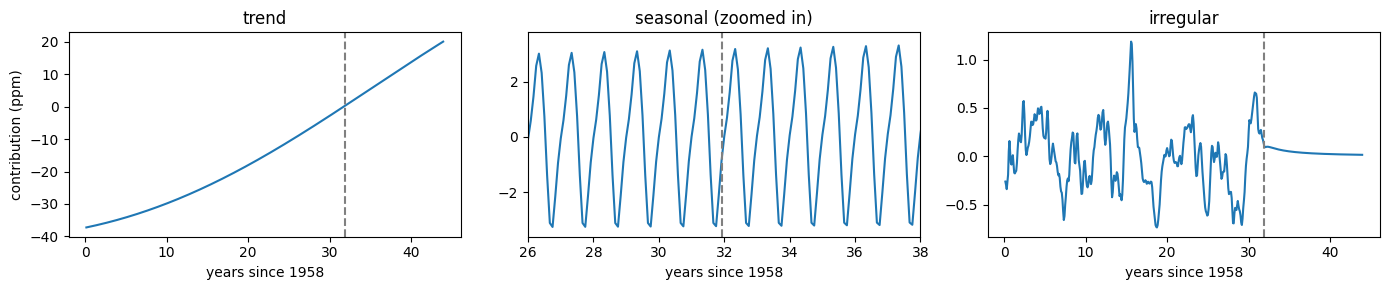

In [12]:
def plot_components(model, x_plot, names, y_std, xlabel="x", xlims=None):
    x_tr, y_tr = model.train_inputs[0], model.train_targets
    model.eval()
    with torch.no_grad():
        K = model.covar_module(x_tr).to_dense() + model.likelihood.noise * torch.eye(len(x_tr))
        weights = torch.linalg.solve(K, y_tr - model.mean_module.constant)
        parts = [k(x_plot, x_tr).to_dense() @ weights for k in model.covar_module.kernels]
    fig, axes = plt.subplots(1, len(parts), figsize=(14, 3))
    for ax, name, part, xlim in zip(axes, names, parts, xlims or [None] * len(parts)):
        ax.plot(x_plot, part * y_std)
        ax.axvline(x_tr[-1].item(), color="gray", ls="--")
        ax.set_title(name)
        ax.set_xlabel(xlabel)
        if xlim:
            ax.set_xlim(*xlim)
    axes[0].set_ylabel("contribution (ppm)")
    plt.tight_layout()
    plt.show()


plot_components(model_co2, x, ["trend", "seasonal (zoomed in)", "irregular"], y_std, "years since 1958",
                xlims=[None, (26, 38), None])

Here is a side-by-side comparison, including a middle ground with only trend and periodicity. Same data, same model class, same training loop. **Only the kernel changes.**

In [13]:
model_mid = train(GPModel(x_train, y_train,
                          ScaleKernel(RBFKernel().initialize(lengthscale=50.0))
                          + ScaleKernel(PeriodicKernel().initialize(period_length=1.0))), iters=300)

results = {
    "RBF": score(model_rbf, x_test, y_test),
    "RBF + Periodic": score(model_mid, x_test, y_test),
    "Trend + Seasonal + Irregular": score(model_co2, x_test, y_test),
}
pd.DataFrame(results, index=["test RMSE", "test NLPD"]).T.round(3)

iter    0   loss 0.841


iter  100   loss -0.279


iter  200   loss -0.286


iter  299   loss -0.288


,test RMSE,test NLPD
RBF,1.484,2.226
RBF + Periodic,0.226,-0.023
Trend + Seasonal + Irregular,0.148,-0.089


### Writing your own kernel

Because GPyTorch is PyTorch, a new kernel is just a class with a `forward` method that returns the covariance matrix. Here is the RBF kernel written from scratch in a few lines. Anything you can write in PyTorch (as long as it gives a valid covariance) can become a kernel. Keep this in mind for Section 5.

In [14]:
class MyRBF(gpytorch.kernels.Kernel):
    has_lengthscale = True  # GPyTorch creates and constrains self.lengthscale for us

    def forward(self, x1, x2, **params):
        sqdist = self.covar_dist(x1 / self.lengthscale, x2 / self.lengthscale, square_dist=True, **params)
        return torch.exp(-0.5 * sqdist)


# It plugs in exactly like a built-in kernel and should match the RBF result above
model_my = train(GPModel(x_train, y_train, ScaleKernel(MyRBF())))
rmse, nlpd = score(model_my, x_test, y_test)
print(f"MyRBF   test RMSE {rmse:.3f}, NLPD {nlpd:.3f}")

iter    0   loss 0.904


iter  100   loss -0.224


iter  200   loss -0.242


iter  299   loss -0.247
MyRBF   test RMSE 1.484, NLPD 2.226


## 4. Your turn with Huawei wireless traffic

Real **uplink traffic** from 30 anonymized wireless cells, every 5 minutes for 7 days. The preprocessing is done for you.
* 15-minute averages, modeled as **log traffic**
* $x$ is in **days**, so a period of 1 means one day
* Train on the first **6 days**, forecast **day 7**

576 training points, 97 test points


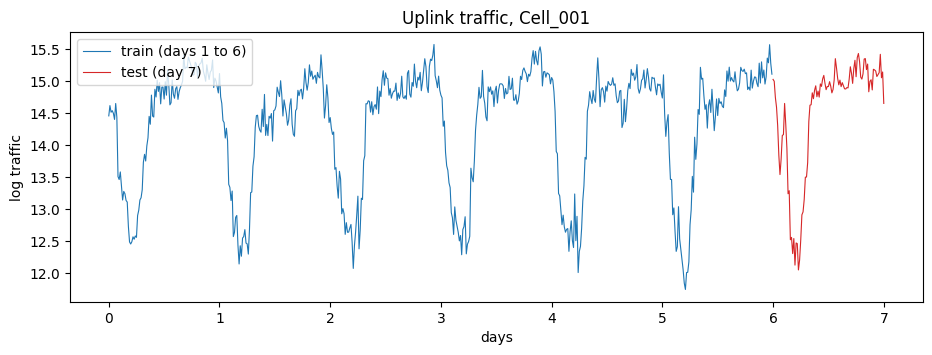

In [15]:
import os

DATA_URL = "https://raw.githubusercontent.com/richardcsuwandi/gp-time-series-tutorial/main/huawei_cell_traffic.csv"
DATA_PATH = "huawei_cell_traffic.csv" if os.path.exists("huawei_cell_traffic.csv") else DATA_URL
traffic = pd.read_csv(DATA_PATH, parse_dates=["timestamp"]).set_index("timestamp")


def load_cell(cell):
    series = traffic[cell].resample("15min").mean()
    days = torch.tensor((series.index - series.index[0]).total_seconds().to_numpy() / 86400)
    y_log = torch.tensor(np.log(series.to_numpy()))
    train_mask = days < 6
    y_mean, y_std = y_log[train_mask].mean(), y_log[train_mask].std()
    y = (y_log - y_mean) / y_std  # standardize with training statistics only
    return days[train_mask], y[train_mask], days[~train_mask], y[~train_mask], y_mean, y_std


CELL = "Cell_001"  # which network cell to model, from Cell_001 to Cell_030
hx_train, hy_train, hx_test, hy_test, hy_mean, hy_std = load_cell(CELL)
print(f"{len(hx_train)} training points, {len(hx_test)} test points")

plt.plot(hx_train, hy_train * hy_std + hy_mean, lw=0.8, label="train (days 1 to 6)")
plt.plot(hx_test, hy_test * hy_std + hy_mean, lw=0.8, color="tab:red", label="test (day 7)")
plt.xlabel("days")
plt.ylabel("log traffic")
plt.title(f"Uplink traffic, {CELL}")
plt.legend(loc="upper left")
plt.show()

### All 30 cells at a glance

Same daily rhythm, but every cell looks a bit different. One hand-made kernel may not suit them all.

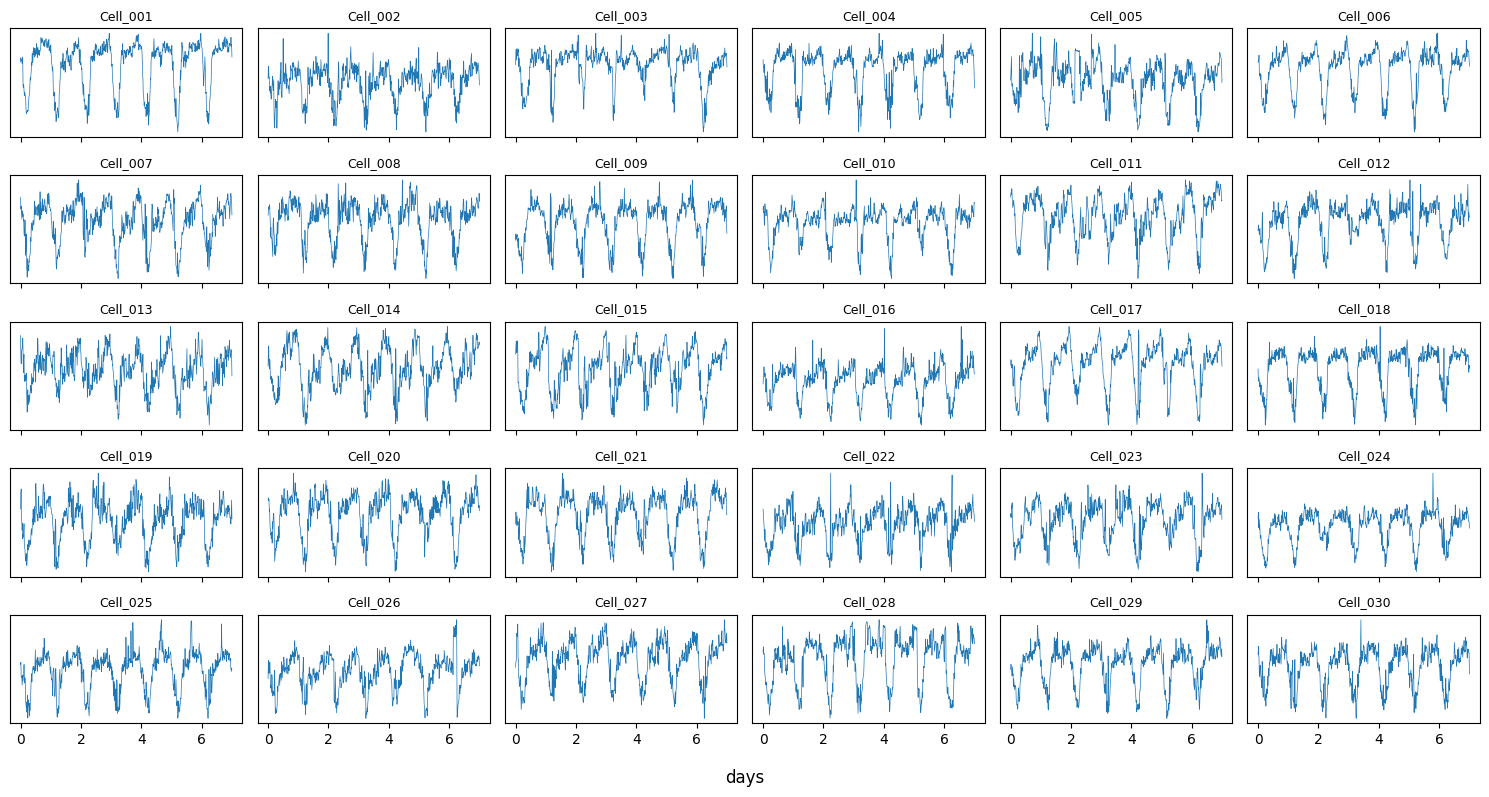

In [16]:
fig, axes = plt.subplots(5, 6, figsize=(15, 8), sharex=True)
for ax, cell in zip(axes.flat, traffic.columns):
    x_c, y_c, x_c_test, y_c_test, _, _ = load_cell(cell)
    ax.plot(torch.cat([x_c, x_c_test]), torch.cat([y_c, y_c_test]), lw=0.5)
    ax.set_title(cell, fontsize=9)
    ax.set_yticks([])
fig.supxlabel("days")
plt.tight_layout()
plt.show()

### Baseline

Here is the plain RBF kernel again.

iter    0   loss 1.415


iter  100   loss 0.124


iter  200   loss 0.120


iter  299   loss 0.120


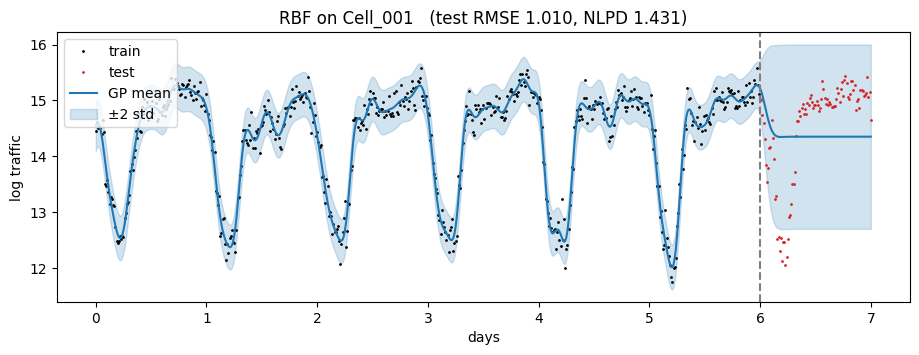

In [17]:
model_h_rbf = train(GPModel(hx_train, hy_train, ScaleKernel(RBFKernel())))
plot_fit(model_h_rbf, hx_train, hy_train, hx_test, hy_test, f"RBF on {CELL}", hy_mean, hy_std, "days", "log traffic")

### ✏️ Exercise. Design a better kernel

The RBF forecast for day 7 is basically flat. Your job is to replace it with a kernel that captures the structure of this data. Some questions to guide you.

1. Look at the plot. What pattern repeats, and how often? What is that period in units of $x$?
2. Is every day exactly the same, or does the daily shape change a bit? Which kernel operation lets a pattern slowly change?
3. Is there short-term fluctuation on top of the daily pattern? Is it smooth or rough?
4. Remember to give periods and lengthscales sensible initial values with `.initialize(...)`.

Edit `custom_kernel()` below and run the next two cells. Try to beat the RBF baseline on both RMSE and NLPD.

iter    0   loss 1.415


iter  100   loss 0.124


iter  200   loss 0.120


iter  299   loss 0.120


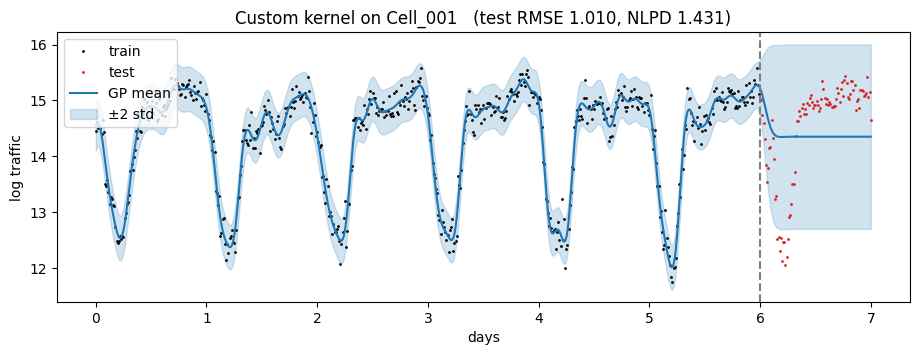

In [18]:
def custom_kernel():
    # TODO: replace this baseline with your own kernel design
    return ScaleKernel(RBFKernel())

model_h_custom = train(GPModel(hx_train, hy_train, custom_kernel()))
plot_fit(model_h_custom, hx_train, hy_train, hx_test, hy_test, f"Custom kernel on {CELL}", hy_mean, hy_std, "days", "log traffic")

In [19]:
pd.DataFrame({
    "RBF baseline": score(model_h_rbf, hx_test, hy_test),
    "Custom kernel": score(model_h_custom, hx_test, hy_test),
}, index=["test RMSE", "test NLPD"]).T.round(3)

,test RMSE,test NLPD
RBF baseline,1.01,1.431
Custom kernel,1.01,1.431


### 🎛️ Try another network cell

Does your kernel still work on a different cell? Change the name below (anything from `Cell_001` to `Cell_030`) and run the cell again.

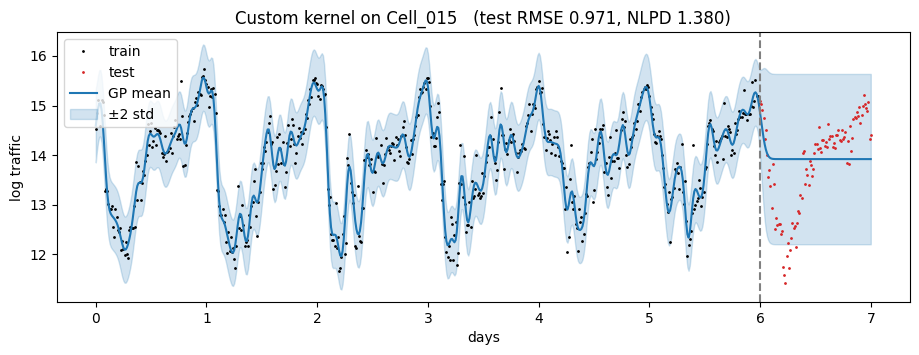

In [20]:
def try_on_cell(cell, make_kernel=custom_kernel):
    x_c, y_c, x_c_test, y_c_test, y_mean_c, y_std_c = load_cell(cell)
    model = train(GPModel(x_c, y_c, make_kernel()), verbose=False)
    plot_fit(model, x_c, y_c, x_c_test, y_c_test, f"Custom kernel on {cell}", y_mean_c, y_std_c, "days", "log traffic")


try_on_cell("Cell_015")

**Things to try after that**
* Compare `MaternKernel(nu=0.5)`, `nu=1.5` and `RBFKernel` for the short-term part.
* What happens if you model raw traffic instead of log traffic?

<details>
<summary><b>Show one possible solution</b> (try it yourself first)</summary>

A daily periodic kernel plus a rough Matérn kernel for short-term fluctuations works well for most cells.

```python
def custom_kernel():
    daily = ScaleKernel(PeriodicKernel().initialize(period_length=1.0))
    short_term = ScaleKernel(MaternKernel(nu=0.5).initialize(lengthscale=0.05))
    return daily + short_term
```

On `Cell_001` this cuts the test RMSE from about 1.0 to about 0.4. Notice that it took several design decisions (which components, how to combine them, how to initialize them) and that the best choice can differ from cell to cell.
</details>

## 5. Can an LLM design the kernel for us?

Designing kernels by hand takes domain knowledge and a lot of trial and error. That is fine for one series, but not for 30 cells (or 3,000 in a real network). In two recent papers, we hand this job to large language models.

### CAKE. LLM-driven kernel evolution

*Adaptive Kernel Design for Bayesian Optimization Is a Piece of CAKE with LLMs* (NeurIPS 2025) · [Paper](https://arxiv.org/abs/2509.17998) · [Code](https://github.com/richardcsuwandi/cake)

![CAKE overview](https://raw.githubusercontent.com/richardcsuwandi/cake/main/assets/cake.png)

* An LLM **mutates and combines** kernel expressions built from the blocks you used above.
* The best-fitting kernels survive, so the "try a sum, try a product" loop runs on its own.

### Kernaut. Coding agents write kernels as programs

*Kernel Autoresearch for Open-Ended Model Discovery* · [Paper](https://arxiv.org/abs/2610.10394) · [Code](https://github.com/richardcsuwandi/kernaut)

![Kernaut overview](https://raw.githubusercontent.com/richardcsuwandi/kernaut/main/assets/method-overview.png)

* A **coding agent** writes new kernels as **PyTorch code**, like `MyRBF` in Section 3.
* A backend checks that each kernel is valid, and an archive keeps the best ones.
* No fixed grammar, so it can find kernels that no human wrote down.

### The kernel Kernaut found for this data

We ran Kernaut on this Huawei dataset. It came back with a **daily pattern** plus two **memory** terms, one short (about 6 minutes) and one longer (about 43 minutes). Here it is as code.

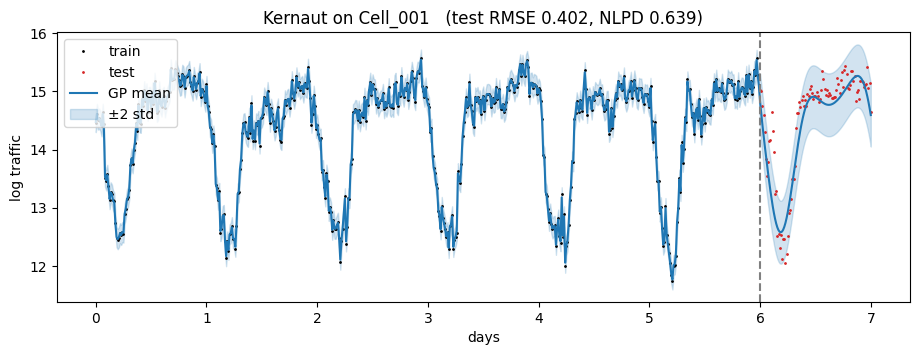

,test RMSE,test NLPD
RBF baseline,1.010,1.431
Custom kernel,1.010,1.431
Hand-designed solution,0.404,0.654
Kernaut,0.402,0.639


In [21]:
def matern32(tau, ell):
    r = math.sqrt(3) * tau / ell
    return (1 + r) * torch.exp(-r)


class KernautKernel(gpytorch.kernels.Kernel):
    """Discovered by Kernaut. All numbers below were chosen by the agent."""

    def forward(self, x1, x2, diag=False, **params):
        tau = self.covar_dist(x1, x2, diag=diag, **params) * 1440  # time lag in minutes
        daily = torch.exp(-2 * torch.sin(math.pi * tau / 1440) ** 2 / 2.4**2)
        short_memory = 0.011 * matern32(tau, 5.75)
        medium_memory = 0.010 * matern32(tau, 42.5)
        return daily + short_memory + medium_memory


def kernaut_kernel():
    return ScaleKernel(KernautKernel())  # GPyTorch only learns the overall scale and the noise


def hand_kernel():  # the solution from Section 4
    daily = ScaleKernel(PeriodicKernel().initialize(period_length=1.0))
    short_term = ScaleKernel(MaternKernel(nu=0.5).initialize(lengthscale=0.05))
    return daily + short_term


model_h_hand = train(GPModel(hx_train, hy_train, hand_kernel()), verbose=False)
model_h_kernaut = train(GPModel(hx_train, hy_train, kernaut_kernel()), verbose=False)
plot_fit(model_h_kernaut, hx_train, hy_train, hx_test, hy_test, f"Kernaut on {CELL}", hy_mean, hy_std, "days", "log traffic")

pd.DataFrame({
    "RBF baseline": score(model_h_rbf, hx_test, hy_test),
    "Custom kernel": score(model_h_custom, hx_test, hy_test),
    "Hand-designed solution": score(model_h_hand, hx_test, hy_test),
    "Kernaut": score(model_h_kernaut, hx_test, hy_test),
}, index=["test RMSE", "test NLPD"]).T.round(3)

🎉 No human in the loop and no tuning for this cell, yet it matches the expert design.

### ✏️ Exercise. Can you beat the agent on all 30 cells?

The next cell scores your `custom_kernel()`, the hand-designed solution and Kernaut on every cell and counts the wins. ⏱️ About 2 minutes.
* Improve `custom_kernel()` in Section 4, then rerun.
* Delete `+ medium_memory` from `KernautKernel`. Does it still win?

Cell_001 done   

Cell_002 done   

Cell_003 done   

Cell_004 done   

Cell_005 done   

...

Cell_026 done   

Cell_027 done   

Cell_028 done   

Cell_029 done   

Cell_030 done   

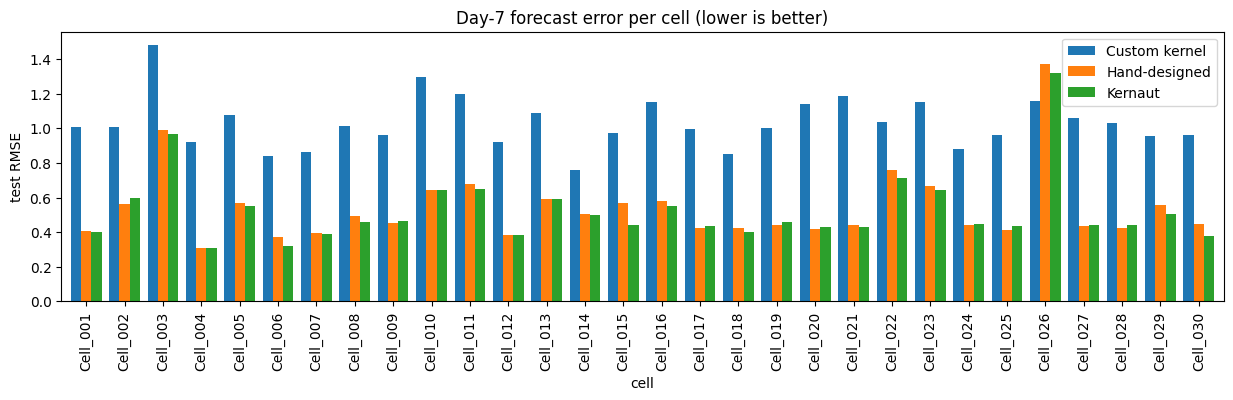

,mean test RMSE,cells won
Custom kernel,1.032,1
Hand-designed,0.539,10
Kernaut,0.523,19


In [22]:
contenders = {"Custom kernel": custom_kernel, "Hand-designed": hand_kernel, "Kernaut": kernaut_kernel}

rows = []
for cell in traffic.columns:
    x_c, y_c, x_c_test, y_c_test, _, _ = load_cell(cell)
    row = {"cell": cell}
    for name, make in contenders.items():
        model = train(GPModel(x_c, y_c, make()), verbose=False)
        row[name] = score(model, x_c_test, y_c_test)[0]  # day-7 test RMSE
    rows.append(row)
    print(cell, "done", end="   ")

board = pd.DataFrame(rows).set_index("cell")
board.plot.bar(figsize=(15, 3.5), width=0.8)
plt.ylabel("test RMSE")
plt.title("Day-7 forecast error per cell (lower is better)")
plt.show()

pd.DataFrame({
    "mean test RMSE": board.mean(),
    "cells won": board.idxmin(axis=1).value_counts().reindex(board.columns, fill_value=0),
}).round(3)

## Wrap-up

**Key takeaways**
* **The kernel is the model.** Same data, same code, only the kernel changed, and the forecast went from a flat line to a good one.
* **Build kernels from what you see.** Give each pattern (trend, seasonality, short-term noise) its own component, and combine them with `+` and `*`.
* **GPyTorch is just PyTorch.** Any valid covariance you can write in a `forward` method is a kernel.
* **Kernel design can be automated.** CAKE evolves kernel expressions with an LLM. Kernaut lets a coding agent write kernels as programs. On this data it discovered a kernel that matches the expert design and beats it on many cells, with no hand tuning at all.

**Want to go further?** Both repositories are open source.
* [CAKE on GitHub](https://github.com/richardcsuwandi/cake)
* [Kernaut on GitHub](https://github.com/richardcsuwandi/kernaut)

A good mini-project is to point Kernaut at a time series you care about and see what it discovers.